In [1]:
import warnings
warnings.filterwarnings('ignore')

import os 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from enigmatoolbox.plotting import plot_cortical, plot_subcortical
from enigmatoolbox.utils.parcellation import parcel_to_surface
import nilearn.plotting

import sys
sys.path.append('..')

from helper.func import general_linear_model

In [2]:
project_dir = os.path.abspath(os.path.join(os.getcwd(), '..'))

In [3]:
from matplotlib.colors import LinearSegmentedColormap
import matplotlib as mpl

my_rdbu = LinearSegmentedColormap.from_list(
    "my_rdbu", ["#174fa0", "#2f89c2", "#f7f7f7", "#df5948", "#ad0c28"], N=256)

try:
    mpl.colormaps.register(my_rdbu)
except ValueError:
    pass

## ENIGMA dataset

In [ ]:
data_dir = os.path.join(project_dir, '...')
results_dir = os.path.join(project_dir, '...')

## demographics
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

## ctx
ctx_allepi = pd.read_csv(os.path.join(results_dir, '...', 'ctx_allepi.csv'), index_col=0)
ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle.csv'), index_col=0)
ctx_ige = pd.read_csv(os.path.join(results_dir, '...', 'ctx_ige.csv'), index_col=0)

## sv
sv_allepi = pd.read_csv(os.path.join(results_dir, '...', 'sv_allepi.csv'), index_col=0)
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle.csv'), index_col=0)
sv_ige = pd.read_csv(os.path.join(results_dir, '...', 'sv_ige.csv'), index_col=0)

## sa
sa_allepi = pd.read_csv(os.path.join(results_dir, '...', 'sa_allepi.csv'), index_col=0)
sa_tle = pd.read_csv(os.path.join(results_dir, '...', 'sa_tle.csv'), index_col=0)
sa_ige = pd.read_csv(os.path.join(results_dir, '...', 'sa_ige.csv'), index_col=0)


### Effect of sex and diagnosis-sex interaction across cohorts

In [5]:
## glm comparison 
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

comparison_types = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

results = {}
for epi in ['tle', 'ige']:
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.biomarker_comparison(
                df_name=df_name, comparison_type=comparison_type, age_col="Age",
                sex_col="Sex", icv_col="ICV", group_col="Dx")

2026-05-28 16:07:33,791 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 16:07:33,798 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 16:07:33,853 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 16:07:33,883 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variabl

In [6]:
# reorganize the results
metrics = ['t', 'q', 'cohen']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

result_dicts = {}
for epi in epi_types:
    for metric in metrics:
        for biomarker in biomarkers:
            key = f"{metric}_{epi}_{biomarker}"
            result_dicts[key] = {}

for epi in epi_types:
    for biomarker in biomarkers:

        t_values = np.vstack([
            results[epi][biomarker]['case_control']['t_values'],
            results[epi][biomarker]['sex_in_epi']['t_values'],
            results[epi][biomarker]['sex_in_hc']['t_values'],
            results[epi][biomarker]['sex_group_interaction']['t_values']
        ])
        result_dicts[f"t_{epi}_{biomarker}"] = t_values

        q_values = np.vstack([
            results[epi][biomarker]['case_control']['q_values'],
            results[epi][biomarker]['sex_in_epi']['q_values'],
            results[epi][biomarker]['sex_in_hc']['q_values'],
            results[epi][biomarker]['sex_group_interaction']['q_values']
        ])
        result_dicts[f"q_{epi}_{biomarker}"] = q_values

        cohen_values = np.vstack([
            results[epi][biomarker]['case_control']['cohen_d'],
            results[epi][biomarker]['sex_in_epi']['cohen_d'],
            results[epi][biomarker]['sex_in_hc']['cohen_d'],
            results[epi][biomarker]['sex_group_interaction']['cohen_d']
        ])
        result_dicts[f"cohen_{epi}_{biomarker}"] = cohen_values

Sex effects in interaction in cortical thickness in TLE

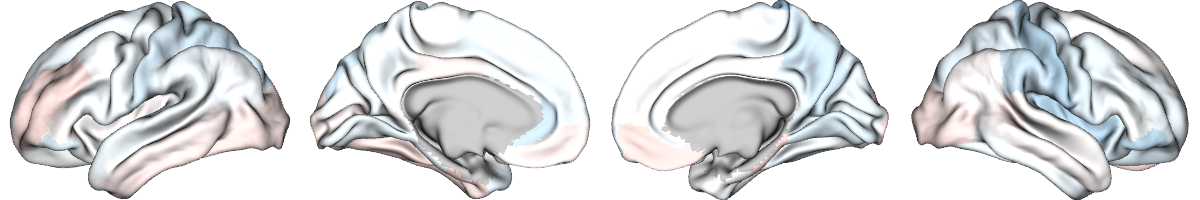

In [7]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

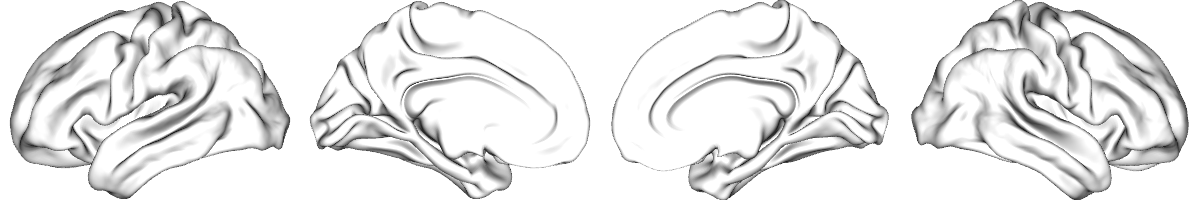

In [9]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [10]:
## Check which areas are significant in epilepsy
q_ctx_hc = pd.Series(result_dicts['q_tle_ctx'][3], index=ctx_tle.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index([], dtype='object')

In [11]:
len(q_ctx_hc[q_ctx_hc < 0.05])

0

In [12]:
# get the cohen's d values range for sex in healthy control
result_dicts['cohen_tle_ctx'][3].min(), result_dicts['cohen_tle_ctx'][3].max()

(-0.056912020034766475, 0.03937227982595228)

subcortical volume

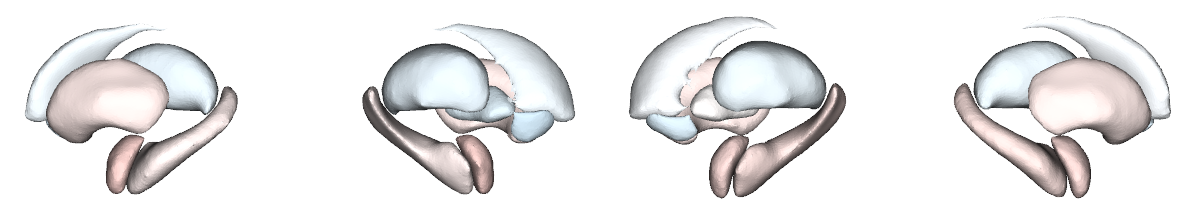

In [14]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_tle_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

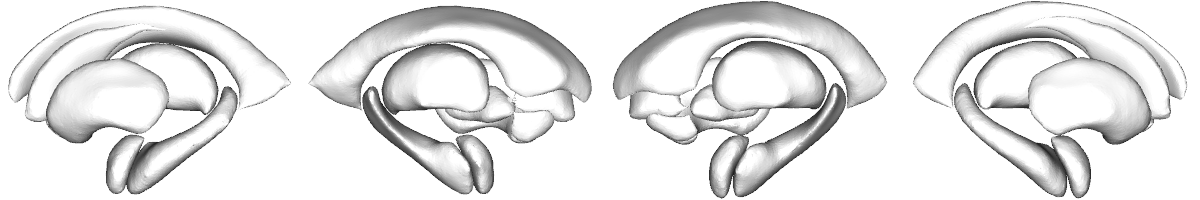

In [15]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1),interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [16]:
## Check which areas are significant in epilepsy
q_sv_inter = pd.Series(result_dicts['q_tle_sv'][3], index=sv_tle.columns, name='pFDR')
q_sv_inter[q_sv_inter < 0.05].index

Index([], dtype='object')

In [17]:
len(q_sv_inter[q_sv_inter < 0.05])

0

In [18]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_sv'][3].min(), result_dicts['cohen_tle_sv'][3].max()

(-0.038295215823178554, 0.046140254413558374)

### Effect of sex and clinical variables interaction across cohorts

In [ ]:
## demographics
demo = pd.read_csv(os.path.join(results_dir, '...', 'demo.csv'))
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

## ctx
ctx_tle = pd.read_csv(os.path.join(results_dir, '...', 'ctx_tle_durill.csv'), index_col=0)
ctx_ige = pd.read_csv(os.path.join(results_dir, '...', 'ctx_ige_durill.csv'), index_col=0)

## sv
sv_tle = pd.read_csv(os.path.join(results_dir, '...', 'sv_tle_durill.csv'), index_col=0)
sv_ige = pd.read_csv(os.path.join(results_dir, '...', 'sv_ige_durill.csv'), index_col=0)

In [22]:
# glm comparison
biomarker_datasets = {
    'ctx': {'tle': ctx_tle, 'ige': ctx_ige},
    'sv': {'tle': sv_tle, 'ige': sv_ige}
}

comparison_types = ['duration', 'duration_sex_interaction', 'ao', 'ao_sex_interaction']

results = {}
for epi in ['tle', 'ige']:
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.clinical_correlate(
                df_name=df_name, comparison_type=comparison_type, durill="durill",
                ao="ao", age="Age", sex="Sex", icv="ICV")

2026-05-28 15:07:10,061 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:07:10,111 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:07:10,159 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:07:10,194 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables

In [23]:
# reorganize the results
metrics = ['t', 'q', 'cohen']
epi_types = ['tle', 'ige']
biomarkers = ['ctx', 'sv']

result_dicts = {}
for epi in epi_types:
    for metric in metrics:
        for biomarker in biomarkers:
            key = f"{metric}_{epi}_{biomarker}"
            result_dicts[key] = {}

for epi in epi_types:
    for biomarker in biomarkers:

        t_values = np.vstack([
            results[epi][biomarker]['duration']['t_values'],
            results[epi][biomarker]['duration_sex_interaction']['t_values'],
            results[epi][biomarker]['ao']['t_values'],
            results[epi][biomarker]['ao_sex_interaction']['t_values']
        ])
        result_dicts[f"t_{epi}_{biomarker}"] = t_values

        q_values = np.vstack([
            results[epi][biomarker]['duration']['q_values'],
            results[epi][biomarker]['duration_sex_interaction']['q_values'],
            results[epi][biomarker]['ao']['q_values'],
            results[epi][biomarker]['ao_sex_interaction']['q_values']
        ])
        result_dicts[f"q_{epi}_{biomarker}"] = q_values

        cohen_values = np.vstack([
            results[epi][biomarker]['duration']['cohen_d'],
            results[epi][biomarker]['duration_sex_interaction']['cohen_d'],
            results[epi][biomarker]['ao']['cohen_d'],
            results[epi][biomarker]['ao_sex_interaction']['cohen_d']
        ])
        result_dicts[f"cohen_{epi}_{biomarker}"] = cohen_values

Sex duration interaction effects in cortical thickness in TLE

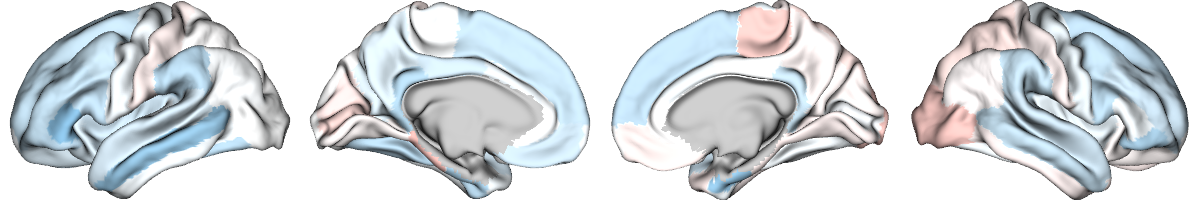

In [24]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

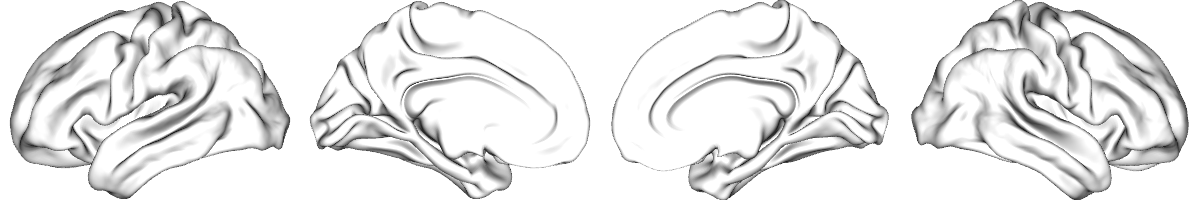

In [25]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [26]:
## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][1], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [27]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [28]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_ctx'][1].min(), result_dicts['cohen_tle_ctx'][1].max()

(-0.09260736143195822, 0.06179479933566267)

Sex * age of onset interaction effects in TLE

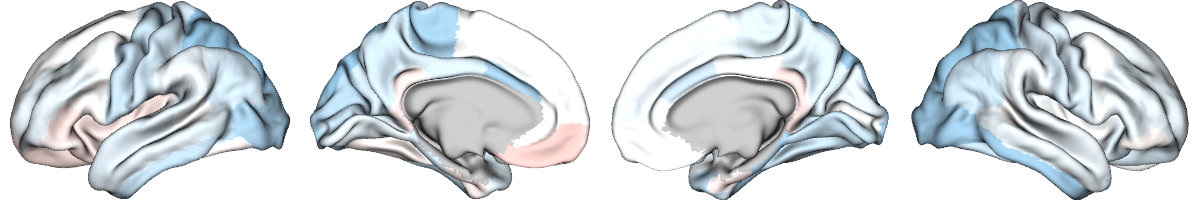

In [30]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

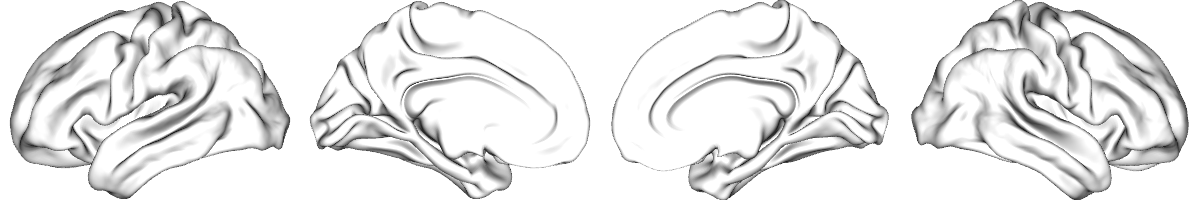

In [31]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [32]:
## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][3], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [33]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [34]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_ctx'][3].min(), result_dicts['cohen_tle_ctx'][3].max()

(-0.08548125206155603, 0.04897426679780324)

sex duration interaction effects in subcortical volume

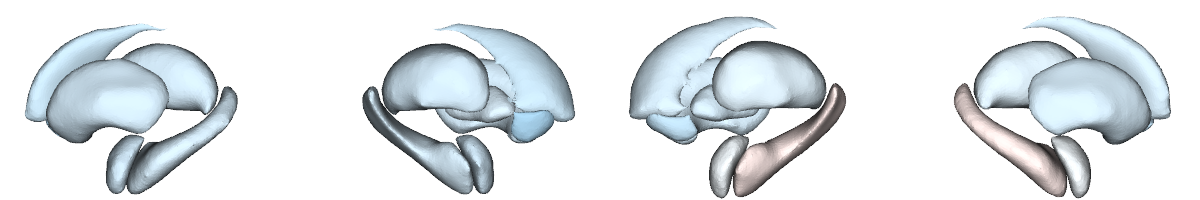

In [ ]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_tle_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

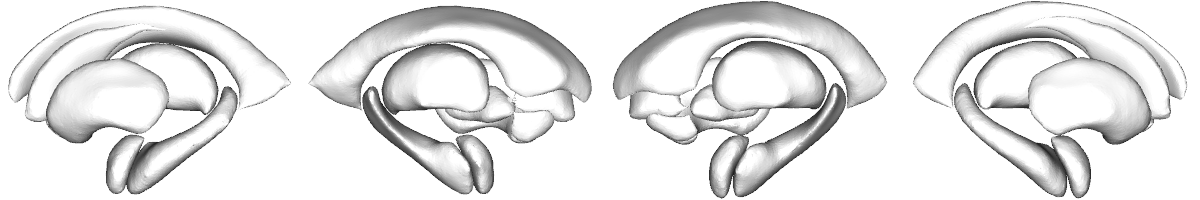

In [37]:
# plot p-sig areas
sig_mask = np.where(result_dicts['q_tle_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [38]:
# sex * disease duration

q_sv_left = pd.Series(
    result_dicts["q_tle_sv"][1],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_left[q_sv_left < 0.05].index

Index([], dtype='object')

In [39]:
result_dicts["cohen_tle_sv"][1].min(), result_dicts["cohen_tle_sv"][1].max()

(-0.07115287726136627, 0.023408859682890904)

Sex* age of onset interaction effects in TLE

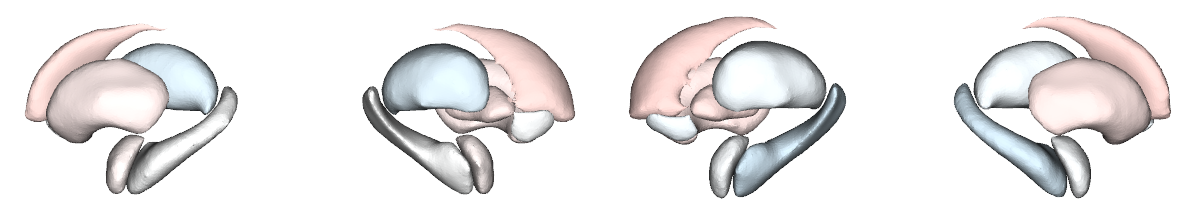

In [41]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_tle_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

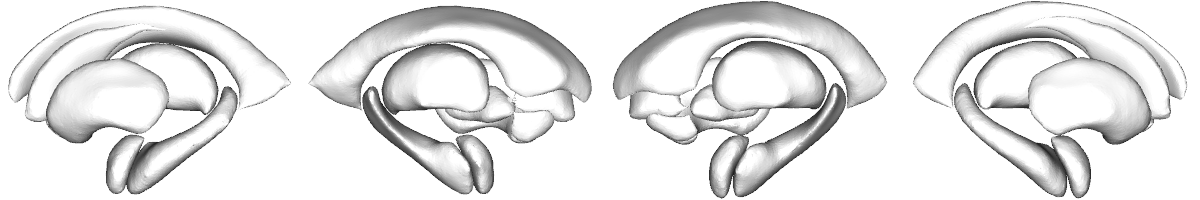

In [42]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [43]:
## Check which areas are significant in epilepsy
q_sv_tle = pd.Series(result_dicts['q_tle_sv'][3], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index([], dtype='object')

In [44]:
len(q_sv_tle[q_sv_tle < 0.05])

0

In [45]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_sv'][3].min(), result_dicts['cohen_tle_sv'][3].max()

(-0.0370470288306561, 0.04275989429690866)

## ECP dataset

In [ ]:
data_dir = os.path.join(project_dir, '...')
results_dir = os.path.join(project_dir, '...')

## demographics
demo = pd.read_csv(os.path.join(data_dir, 'cov_cortex_matched.csv'), index_col=0)
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

## metrics
ctx_tle = pd.read_csv(os.path.join(data_dir, 'ctx_ecp.csv'), index_col=0)
ctx_tle = ctx_tle.iloc[:, 2:]

sv_tle = pd.read_csv(os.path.join(data_dir, 'sv_ecp.csv'), index_col=0)
sv_tle = sv_tle.iloc[:, 2:]

### Effect of sex and diagnosis-sex interaction across cohorts 

In [67]:
## glm comparison 
biomarker_datasets = {'ctx': {'tle': ctx_tle}, 'sv': {'tle': sv_tle}}

comparison_types = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

results = {}

for epi in ['tle']:
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.biomarker_comparison(
                df_name=df_name, comparison_type=comparison_type, age_col="Age",
                sex_col="Sex", icv_col="ICV", group_col="Dx")

2026-05-28 15:27:01,065 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:27:01,072 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:27:01,095 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:27:01,112 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variabl

In [68]:
# reorganize the results
# comparison_types = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

metrics = ['t', 'q', 'cohen']
epi_types = ['tle']  
biomarkers = ['ctx', 'sv']

result_dicts = {}

for epi in epi_types:
    for metric in metrics:
        for biomarker in biomarkers:
            key = f"{metric}_{epi}_{biomarker}"
            result_dicts[key] = {}

for epi in epi_types:
    for biomarker in biomarkers:

        t_values = np.vstack([
            results[epi][biomarker]['case_control']['t_values'],
            results[epi][biomarker]['sex_in_epi']['t_values'],
            results[epi][biomarker]['sex_in_hc']['t_values'],
            results[epi][biomarker]['sex_group_interaction']['t_values']
        ])
        result_dicts[f"t_{epi}_{biomarker}"] = t_values
        
        q_values = np.vstack([
            results[epi][biomarker]['case_control']['q_values'],
            results[epi][biomarker]['sex_in_epi']['q_values'],
            results[epi][biomarker]['sex_in_hc']['q_values'],
            results[epi][biomarker]['sex_group_interaction']['q_values']
        ])
        result_dicts[f"q_{epi}_{biomarker}"] = q_values

        cohen_values = np.vstack([
            results[epi][biomarker]['case_control']['cohen_d'],
            results[epi][biomarker]['sex_in_epi']['cohen_d'],
            results[epi][biomarker]['sex_in_hc']['cohen_d'],
            results[epi][biomarker]['sex_group_interaction']['cohen_d']
        ])
        result_dicts[f"cohen_{epi}_{biomarker}"] = cohen_values

Sex effects in interaction in cortical thickness in TLE

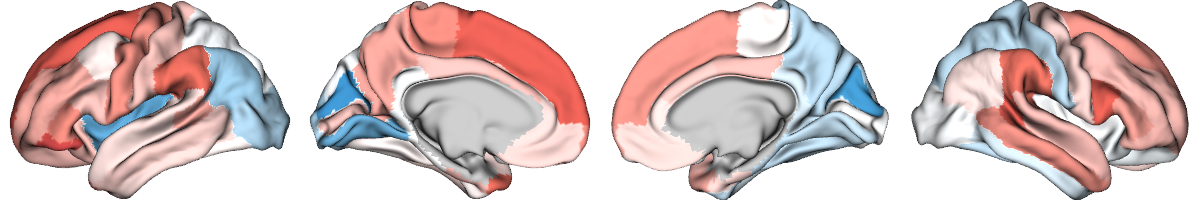

In [69]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

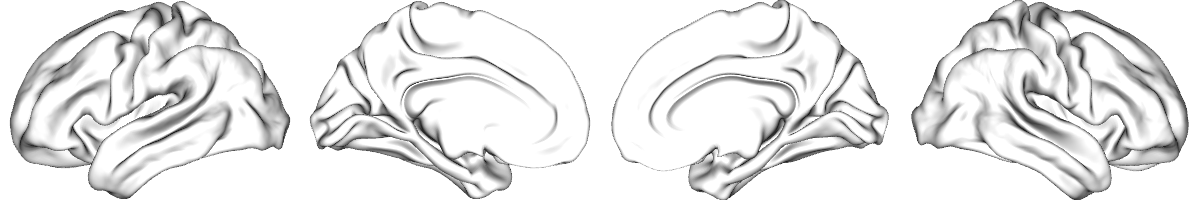

In [70]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [71]:
## Check which areas are significant in epilepsy
q_ctx_hc = pd.Series(result_dicts['q_tle_ctx'][3], index=ctx_tle.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index([], dtype='object')

In [72]:
len(q_ctx_hc[q_ctx_hc < 0.05])

0

In [73]:
# get the cohen's d values range for sex in healthy control
result_dicts['cohen_tle_ctx'][3].min(), result_dicts['cohen_tle_ctx'][3].max()

(-0.16247326232003584, 0.20472405545864017)

Subcortical volume

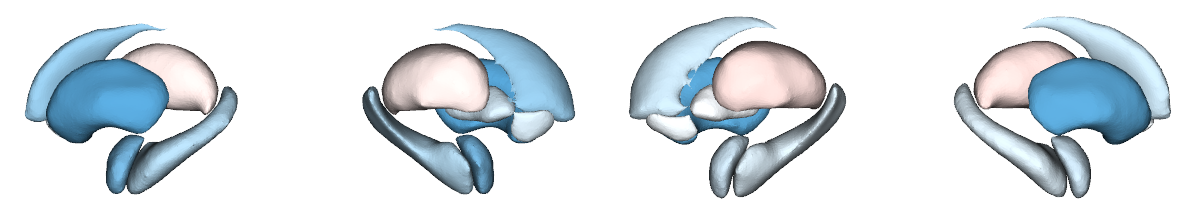

In [74]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_tle_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

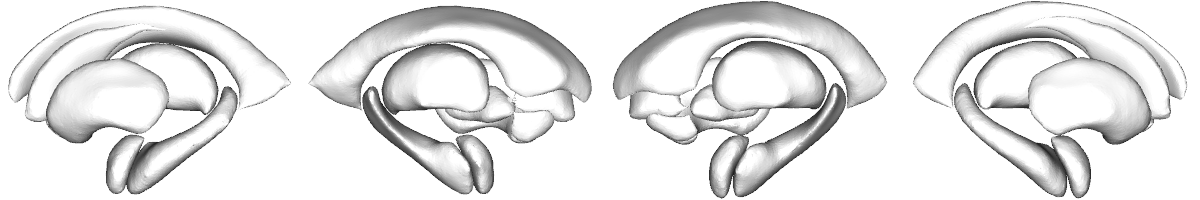

In [75]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1),interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [76]:
## Check which areas are significant in epilepsy
q_sv_tle = pd.Series(result_dicts['q_tle_sv'][3], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index([], dtype='object')

In [77]:
len(q_sv_tle[q_sv_tle < 0.05])

0

In [78]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_sv'][3].min(), result_dicts['cohen_tle_sv'][3].max()

(-0.13139290778096124, 0.03344257181667642)

### Effect of sex and clinical variables interaction across cohorts

In [83]:
## demographics
demo = pd.read_csv(os.path.join(data_dir, 'cov_cortex_matched.csv'), index_col=0)
demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')
demo = demo.dropna(subset=['ao'])

## metrics
ctx_tle = pd.read_csv(os.path.join(data_dir, 'ctx_ecp.csv'), index_col=0)
ctx_tle = ctx_tle.iloc[:, 2:]
ctx_tle = ctx_tle.loc[demo.index]

sv_tle = pd.read_csv(os.path.join(data_dir, 'sv_ecp.csv'), index_col=0)
sv_tle = sv_tle.iloc[:, 2:]
sv_tle = sv_tle.loc[demo.index]


In [84]:
# glm comparison
biomarker_datasets = {'ctx': {'tle': ctx_tle}, 'sv': {'tle': sv_tle}}

comparison_types = ['duration', 'duration_sex_interaction', 'ao', 'ao_sex_interaction']

results = {}
for epi in ['tle']:  
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.clinical_correlate(
                df_name=df_name, comparison_type=comparison_type, durill="durill",
                ao="ao", age="Age", sex="Sex", icv="ICV")

2026-05-28 15:37:46,485 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:37:46,513 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:37:46,545 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:37:46,575 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables

In [85]:
# reorganize the results
metrics = ['t', 'q', 'cohen']
epi_types = ['tle']  
biomarkers = ['ctx', 'sv']

result_dicts = {}
for epi in epi_types:
    for metric in metrics:
        for biomarker in biomarkers:
            key = f"{metric}_{epi}_{biomarker}"
            result_dicts[key] = {}

for epi in epi_types:
    for biomarker in biomarkers:

        t_values = np.vstack([
            results[epi][biomarker]['duration']['t_values'],
            results[epi][biomarker]['duration_sex_interaction']['t_values'],
            results[epi][biomarker]['ao']['t_values'],
            results[epi][biomarker]['ao_sex_interaction']['t_values']
        ])
        result_dicts[f"t_{epi}_{biomarker}"] = t_values

        q_values = np.vstack([
            results[epi][biomarker]['duration']['q_values'],
            results[epi][biomarker]['duration_sex_interaction']['q_values'],
            results[epi][biomarker]['ao']['q_values'],
            results[epi][biomarker]['ao_sex_interaction']['q_values']
        ])
        result_dicts[f"q_{epi}_{biomarker}"] = q_values

        cohen_values = np.vstack([
            results[epi][biomarker]['duration']['cohen_d'],
            results[epi][biomarker]['duration_sex_interaction']['cohen_d'],
            results[epi][biomarker]['ao']['cohen_d'],
            results[epi][biomarker]['ao_sex_interaction']['cohen_d']
        ])
        result_dicts[f"cohen_{epi}_{biomarker}"] = cohen_values

Sex duration interaction effects in cortical thickness in TLE

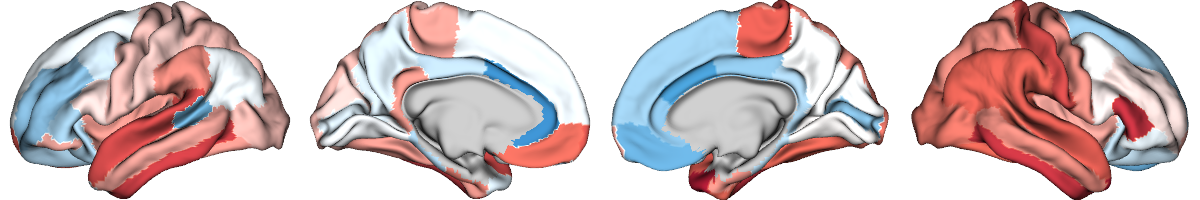

In [86]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

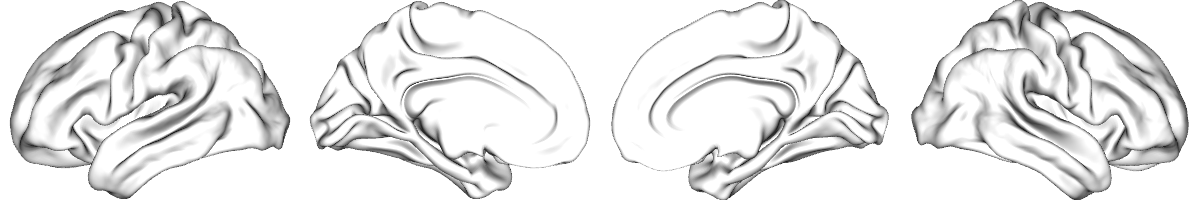

In [87]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [88]:
## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][1], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [89]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [90]:
# get the cohen's d values range for sex in healthy control
result_dicts['cohen_tle_ctx'][1].min(), result_dicts['cohen_tle_ctx'][1].max()

(-0.17950285550725148, 0.3151515190932678)

Sex*age of onset interaction effects

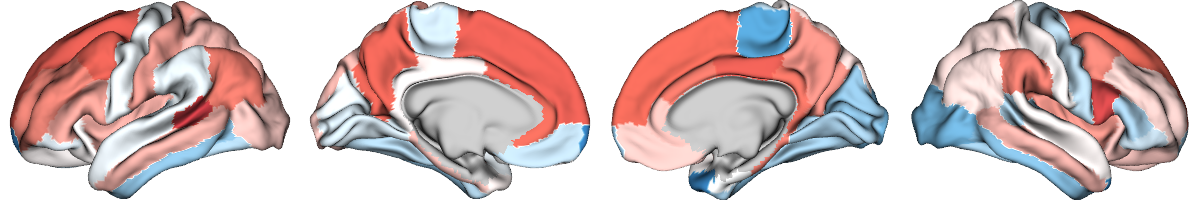

In [92]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

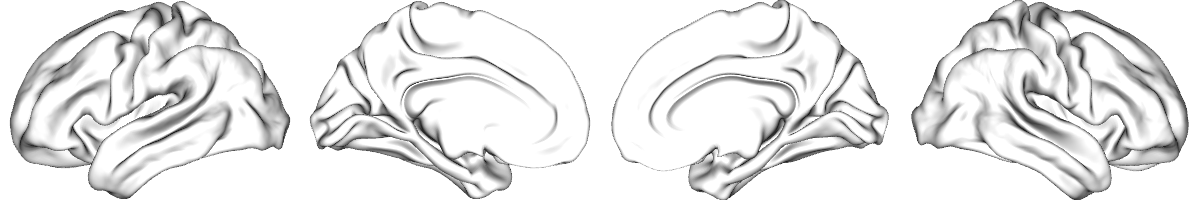

In [93]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [94]:
## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][3], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [95]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [96]:
# get the cohen's d values range for sex in healthy control
result_dicts['cohen_tle_ctx'][3].min(), result_dicts['cohen_tle_ctx'][3].max()

(-0.20436105710199184, 0.23246393846936989)

sex duration interaction effects in subcortical volume

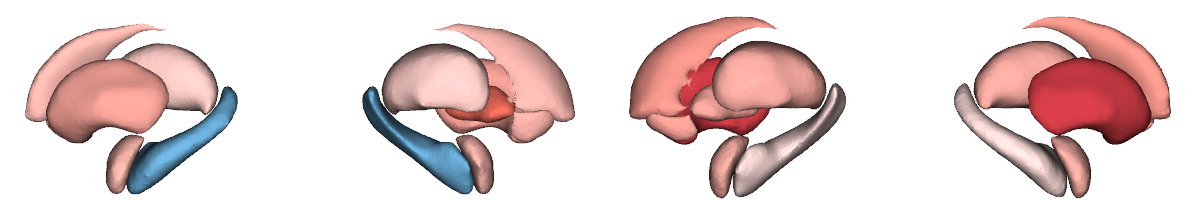

In [98]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_tle_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))


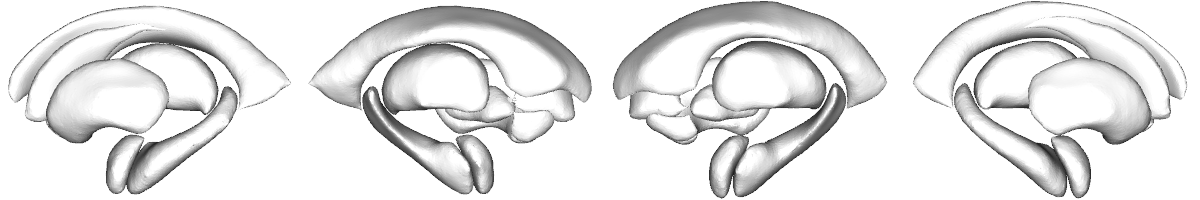

In [99]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [100]:
# sex * disease duration 

q_sv_left = pd.Series(
    result_dicts["q_tle_sv"][1],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_left[q_sv_left < 0.05].index

Index([], dtype='object')

In [101]:
result_dicts["cohen_tle_sv"][1].min(), result_dicts["cohen_tle_sv"][1].max()

(-0.11556924738727074, 0.24027460506901924)

Sex age of onset interaction effects

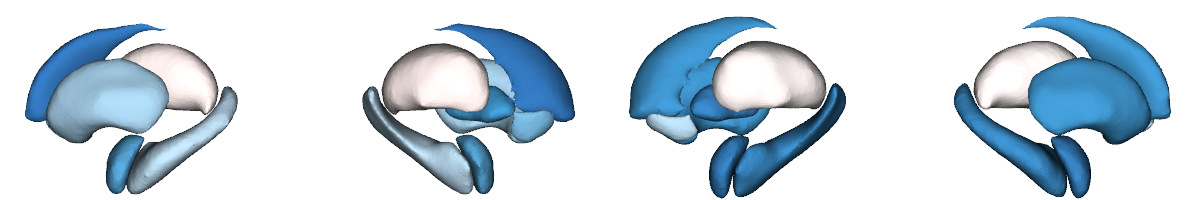

In [104]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_tle_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

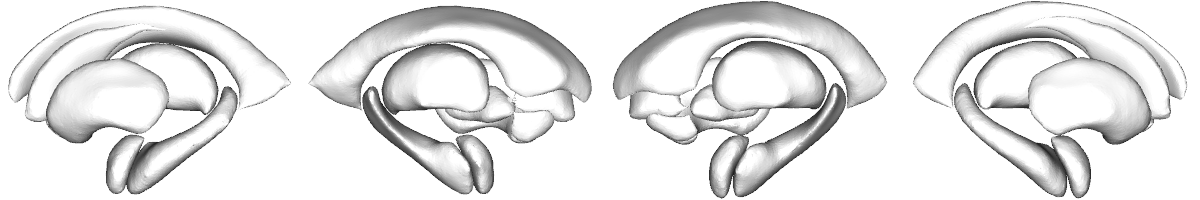

In [105]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [106]:
## Check which areas are significant in epilepsy
q_sv_hc = pd.Series(result_dicts['q_tle_sv'][3], index=sv_tle.columns, name='pFDR')
q_sv_hc[q_sv_hc < 0.05].index

Index([], dtype='object')

In [107]:
len(q_sv_hc[q_sv_hc < 0.05])

0

In [108]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_sv'][3].min(), result_dicts['cohen_tle_sv'][3].max()

(-0.24032703926328028, 0.018646280474603923)

## MNI dataset

In [ ]:
data_dir = os.path.join(project_dir, '...')
results_dir = os.path.join(project_dir, '...')

In [111]:
## demographics
demo = pd.read_csv(os.path.join(data_dir, 'demo.csv'), index_col=0)
# demo['Dx'] = pd.to_numeric(demo['Dx'], errors='coerce')

## metrics
ctx_tle = pd.read_csv(os.path.join(data_dir, 'ctx.csv'), index_col=0)
ctx_tle = ctx_tle.iloc[:, 1:]

sv_tle = pd.read_csv(os.path.join(data_dir, 'sv.csv'), index_col=0)
sv_tle = sv_tle.iloc[:, 1:]

sa_tle = pd.read_csv(os.path.join(data_dir, 'sa.csv'), index_col=0)
sa_tle = sa_tle.iloc[:, 1:]

### Effect of sex and diagnosis-sex interaction across cohorts

In [112]:
## glm comparison 
biomarker_datasets = {'ctx': {'tle': ctx_tle}, 'sv': {'tle': sv_tle}}

comparison_types = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

results = {}

for epi in ['tle']:
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.biomarker_comparison(
                df_name=df_name, comparison_type=comparison_type, age_col="Age",
                sex_col="Sex", icv_col="ICV", group_col="Dx")

2026-05-28 15:44:52,033 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:44:52,040 - brainstat - WARNING - group has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:44:52,061 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:44:52,076 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variabl

In [113]:
# reorganize the results
metrics = ['t', 'q', 'cohen']
epi_types = ['tle']  
biomarkers = ['ctx', 'sv']

result_dicts = {}

for epi in epi_types:
    for metric in metrics:
        for biomarker in biomarkers:
            key = f"{metric}_{epi}_{biomarker}"
            result_dicts[key] = {}

for epi in epi_types:
    for biomarker in biomarkers:

        t_values = np.vstack([
            results[epi][biomarker]['case_control']['t_values'],
            results[epi][biomarker]['sex_in_epi']['t_values'],
            results[epi][biomarker]['sex_in_hc']['t_values'],
            results[epi][biomarker]['sex_group_interaction']['t_values']
        ])
        result_dicts[f"t_{epi}_{biomarker}"] = t_values

        q_values = np.vstack([
            results[epi][biomarker]['case_control']['q_values'],
            results[epi][biomarker]['sex_in_epi']['q_values'],
            results[epi][biomarker]['sex_in_hc']['q_values'],
            results[epi][biomarker]['sex_group_interaction']['q_values']
        ])
        result_dicts[f"q_{epi}_{biomarker}"] = q_values

        cohen_values = np.vstack([
            results[epi][biomarker]['case_control']['cohen_d'],
            results[epi][biomarker]['sex_in_epi']['cohen_d'],
            results[epi][biomarker]['sex_in_hc']['cohen_d'],
            results[epi][biomarker]['sex_group_interaction']['cohen_d']
        ])
        result_dicts[f"cohen_{epi}_{biomarker}"] = cohen_values

Sex effects in interaction in cortical thickness in TLE

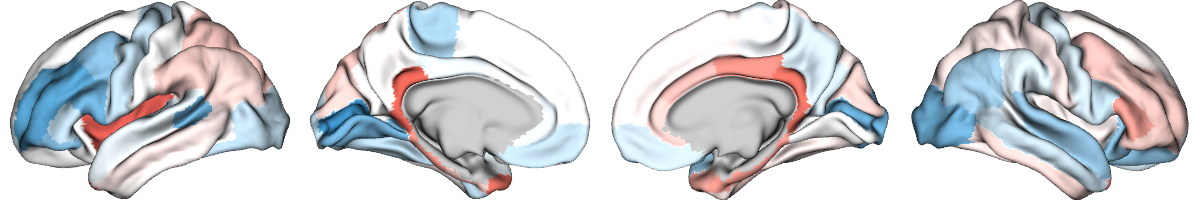

In [114]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

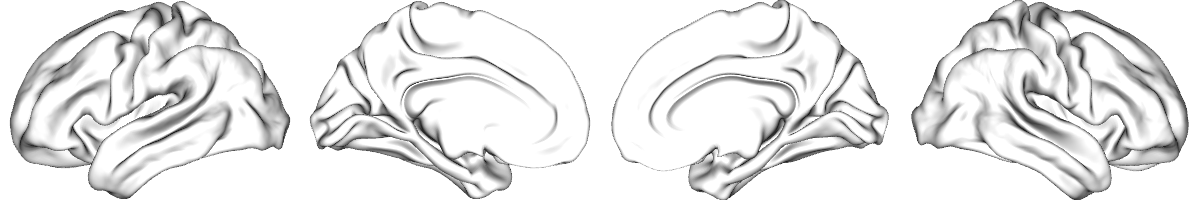

In [116]:
# plot p-sig areas
p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [117]:
## Check which areas are significant in epilepsy
q_ctx_hc = pd.Series(result_dicts['q_tle_ctx'][3], index=ctx_tle.columns, name='pFDR')
q_ctx_hc[q_ctx_hc < 0.05].index

Index([], dtype='object')

In [119]:
# get the cohen's d values range for sex in healthy control
result_dicts['cohen_tle_ctx'][3].min(), result_dicts['cohen_tle_ctx'][3].max()

(-0.16071958836722122, 0.17132355981849354)

subcortical volume

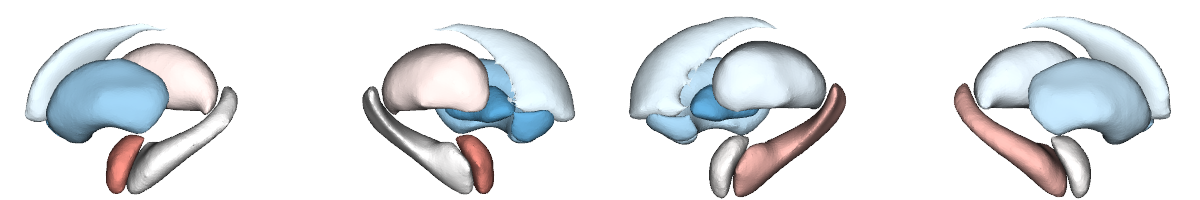

In [121]:
# plot cohen values
# label_text = ['case_control', 'sex_in_epi', 'sex_in_hc', 'sex_group_interaction']

plot_subcortical(result_dicts['cohen_tle_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

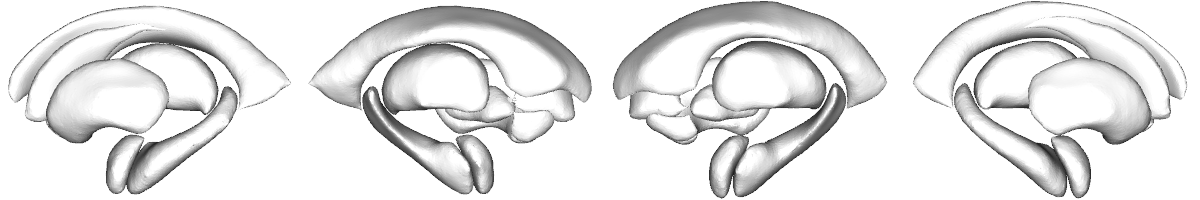

In [122]:
# plot p-sig regions

sig_mask = np.where(result_dicts['q_tle_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1),interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [123]:
## Check which areas are significant in epilepsy
q_sv_inter = pd.Series(result_dicts['q_tle_sv'][3], index=sv_tle.columns, name='pFDR')
q_sv_inter[q_sv_inter < 0.05].index

Index([], dtype='object')

In [124]:
len(q_sv_inter[q_sv_inter < 0.05])

0

In [125]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_sv'][3].min(), result_dicts['cohen_tle_sv'][3].max()

(-0.130124153158333, 0.1128420355370476)

### Effect of sex and clinical variables interaction across cohorts

In [ ]:
## demographics
demo = pd.read_csv(os.path.join(data_dir, 'demo.csv'), index_col=0)
demo = demo.dropna(subset=['ao'])

## metrics
ctx_tle = pd.read_csv(os.path.join(data_dir, 'ctx.csv'), index_col=0)
ctx_tle = ctx_tle.iloc[:, 1:]
ctx_tle = ctx_tle.loc[demo.index]

sv_tle = pd.read_csv(os.path.join(data_dir, 'sv.csv'), index_col=0)
sv_tle = sv_tle.iloc[:, 1:]
sv_tle = sv_tle.loc[demo.index]

sa_tle = pd.read_csv(os.path.join(data_dir, 'sa.csv'), index_col=0)
sa_tle = sa_tle.iloc[:, 1:]
sa_tle = sa_tle.loc[demo.index]

In [132]:
# glm comparison
biomarker_datasets = {'ctx': {'tle': ctx_tle}, 'sv': {'tle': sv_tle}}

comparison_types = ['duration', 'duration_sex_interaction', 'ao', 'ao_sex_interaction']

results = {}
for epi in ['tle']:  
    results[epi] = {}
    for biomarker in ['ctx', 'sv']:
        results[epi][biomarker] = {}

for biomarker, biomarker_dfs in biomarker_datasets.items():
    for epi, biomarker_df in biomarker_dfs.items():
        glm = general_linear_model(demo, biomarker_df)
        df_name = f"{biomarker}_{epi}"

        for comparison_type in comparison_types:
            results[epi][biomarker][comparison_type] = glm.clinical_correlate(
                df_name=df_name, comparison_type=comparison_type, durill="durill",
                ao="ao", age="Age", sex="Sex", icv="ICV")

2026-05-28 15:50:09,089 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:50:09,119 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:50:09,149 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables is to convert numerics to strings.
2026-05-28 15:50:09,174 - brainstat - WARNING - sex has 2 unique values but was supplied as a numeric (i.e. continuous) variable. Should it be a categorical variable? If yes, the easiest way to provide categorical variables

In [133]:
# reorganize the results
metrics = ['t', 'q', 'cohen']
epi_types = ['tle']  
biomarkers = ['ctx', 'sv']

result_dicts = {}
for epi in epi_types:
    for metric in metrics:
        for biomarker in biomarkers:
            key = f"{metric}_{epi}_{biomarker}"
            result_dicts[key] = {}

for epi in epi_types:
    for biomarker in biomarkers:

        t_values = np.vstack([
            results[epi][biomarker]['duration']['t_values'],
            results[epi][biomarker]['duration_sex_interaction']['t_values'],
            results[epi][biomarker]['ao']['t_values'],
            results[epi][biomarker]['ao_sex_interaction']['t_values']
        ])
        result_dicts[f"t_{epi}_{biomarker}"] = t_values

        q_values = np.vstack([
            results[epi][biomarker]['duration']['q_values'],
            results[epi][biomarker]['duration_sex_interaction']['q_values'],
            results[epi][biomarker]['ao']['q_values'],
            results[epi][biomarker]['ao_sex_interaction']['q_values']
        ])
        result_dicts[f"q_{epi}_{biomarker}"] = q_values

        cohen_values = np.vstack([
            results[epi][biomarker]['duration']['cohen_d'],
            results[epi][biomarker]['duration_sex_interaction']['cohen_d'],
            results[epi][biomarker]['ao']['cohen_d'],
            results[epi][biomarker]['ao_sex_interaction']['cohen_d']
        ])
        result_dicts[f"cohen_{epi}_{biomarker}"] = cohen_values


Sex duration interaction effects in cortical thickness in TLE

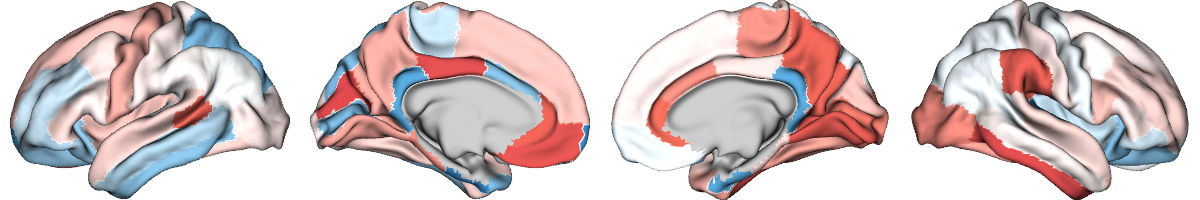

In [134]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][1], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

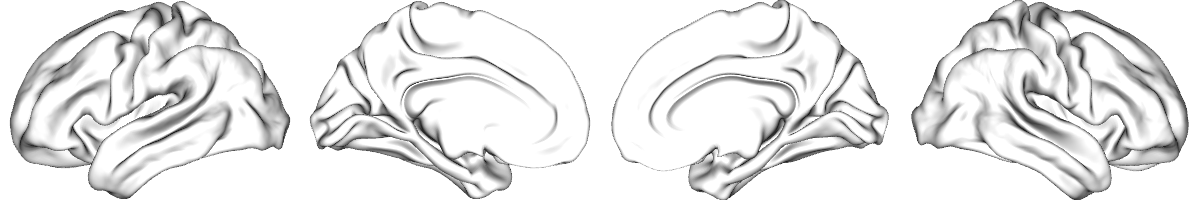

In [135]:
# plot p-sig areas

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][1], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [136]:
## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][1], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [137]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [138]:
# get the cohen's d values range for sex in healthy control
result_dicts['cohen_tle_ctx'][1].min(), result_dicts['cohen_tle_ctx'][1].max()

(-0.20639790019962317, 0.21861395351260057)

Sex*age of onset interaction effects

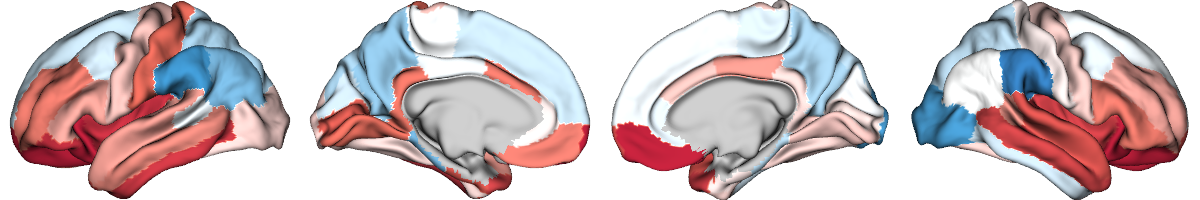

In [140]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

cohen_ctx_surf = parcel_to_surface(result_dicts['cohen_tle_ctx'][3], 'aparc_conte69')
cohen_ctx_surf[cohen_ctx_surf==0] = np.nan

plot_cortical(array_name=cohen_ctx_surf, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(0.7, 0.7, 0.7, 1), embed_nb=True, interactive=True,
              cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

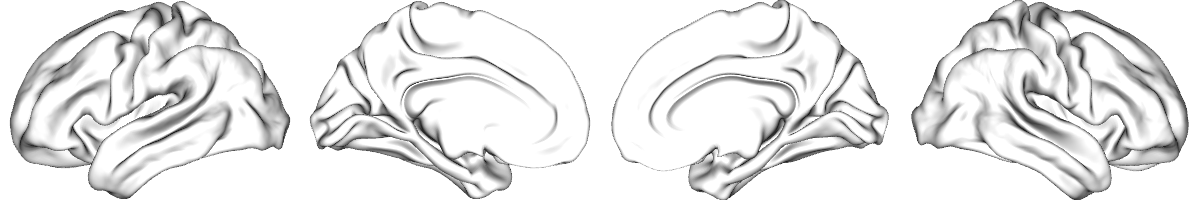

In [141]:
# plot p-sig regions

p_ctx_surf = parcel_to_surface(result_dicts['q_tle_ctx'][3], 'aparc_conte69')
p_ctx_surf[p_ctx_surf==0] = np.nan

sig_mask = np.where(p_ctx_surf <= 0.05, 1, np.nan)

plot_cortical(array_name=sig_mask, surface_name='conte69', size=(1200, 200), zoom=1.8, nan_color=(1, 1, 1, 1), embed_nb=True, interactive=True,
              cmap='Blues', color_bar=False, color_range=(0, 1))

In [142]:
## Check which areas are significant in epilepsy
q_ctx_tle = pd.Series(result_dicts['q_tle_ctx'][3], index=ctx_tle.columns, name='pFDR')
q_ctx_tle[q_ctx_tle < 0.05].index

Index([], dtype='object')

In [143]:
len(q_ctx_tle[q_ctx_tle < 0.05])

0

In [144]:
# get the cohen's d values range for sex in healthy control
result_dicts['cohen_tle_ctx'][3].min(), result_dicts['cohen_tle_ctx'][3].max()

(-0.21033808723175298, 0.3523282189128515)

sex duration interaction effects in subcortical volume

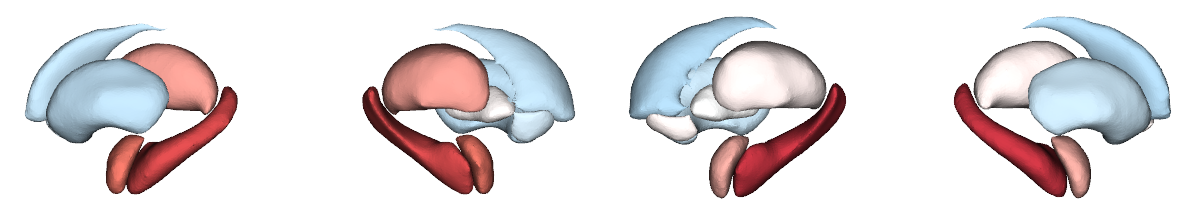

In [146]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_tle_sv'][1], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

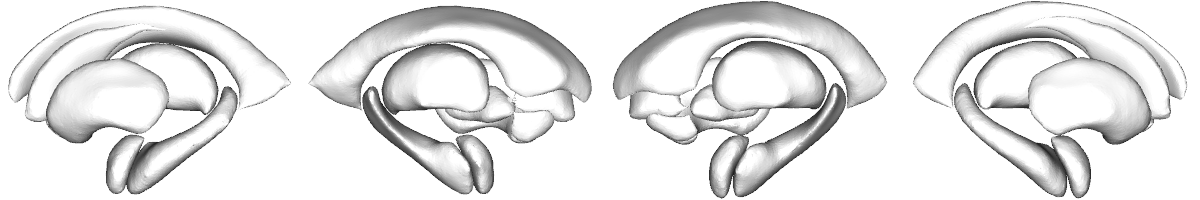

In [147]:
# plot p-sig areas

sig_mask = np.where(result_dicts['q_tle_sv'][1] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [148]:
# sex * disease duration

q_sv_left = pd.Series(
    result_dicts["q_tle_sv"][1],
    index=sv_tle.columns,
    name="pFDR"
)

q_sv_left[q_sv_left < 0.05].index

Index([], dtype='object')

In [149]:
result_dicts["cohen_tle_sv"][1].min(), result_dicts["cohen_tle_sv"][1].max()

(-0.06522694352355522, 0.25149103620168484)

Sex* age of onset interaction effects in TLE

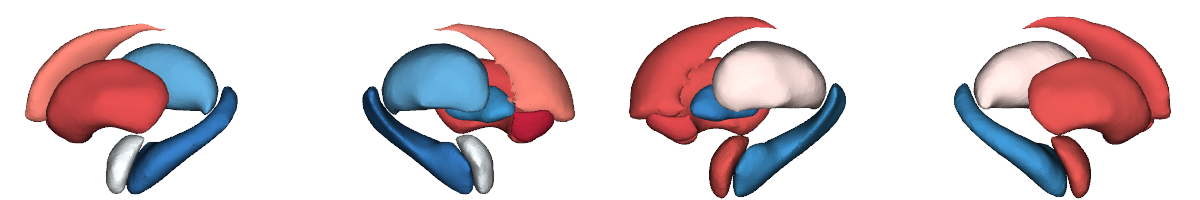

In [151]:
# plot cohen values
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

plot_subcortical(result_dicts['cohen_tle_sv'][3], size=(1200, 200), zoom=1.8, interactive=False, embed_nb=True, ventricles=False,
                label_text = None, cmap='my_rdbu', color_bar=False, color_range=(-0.3, 0.3))

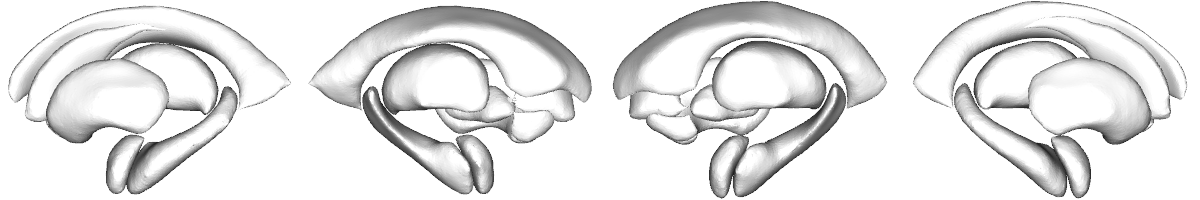

In [152]:
# plot p-sig regions
# label_text = ['sex + durill', 'sex * durill', 'sex + ao', 'sex * ao']

sig_mask = np.where(result_dicts['q_tle_sv'][3] <= 0.05, 1, np.nan)

plot_subcortical(sig_mask, size=(1200, 200), zoom=1.8, nan_color=(1,1,1,1), interactive=False, embed_nb=True, ventricles=False,
                 label_text = None, cmap='Blues', color_bar=False, color_range=(0, 1))

In [153]:
## Check which areas are significant in epilepsy
q_sv_tle = pd.Series(result_dicts['q_tle_sv'][3], index=sv_tle.columns, name='pFDR')
q_sv_tle[q_sv_tle < 0.05].index

Index([], dtype='object')

In [154]:
len(q_sv_tle[q_sv_tle < 0.05])

0

In [155]:
# get the cohen's d values range for sex in epilepsy
result_dicts['cohen_tle_sv'][3].min(), result_dicts['cohen_tle_sv'][3].max()

(-0.23461368305249106, 0.29562503100626386)